# <font color='#FF8585'>Разработка A/B-тестирования и анализ результатов

Работа с компанией, которая разрабатывает развлекательное приложение с функцией "бесконечной" ленты, как, например, в приложениях с короткими видео. В приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Они просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## <font color='#FF8585'>Описание данных

Будем работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа.


## <font color='#FF8585'>Что нужно сделать
**Задача:** рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### <font color='#FF8585'>Работа с историческими данными (EDA)

#### <font color='#FF8585'>Загрузка исторических данных
На этом этапе поработаем с историческими данными приложения.

1. <font color='#3127F5'>Импортируем всё необходимое для работы:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest
from scipy import stats
from math import ceil

2. <font color='#3127F5'>Сохраним в датафрейм CSV-файл с историческими данными о сессиях пользователей и выведем первые 5 строк:

In [2]:
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


3. <font color='#3127F5'>Выведем информацию о датафрейме:

In [3]:
sessions_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   user_id            435924 non-null  str  
 1   session_id         435924 non-null  str  
 2   session_date       435924 non-null  str  
 3   session_start_ts   435924 non-null  str  
 4   install_date       435924 non-null  str  
 5   session_number     435924 non-null  int64
 6   registration_flag  435924 non-null  int64
 7   page_counter       435924 non-null  int64
 8   region             435924 non-null  str  
 9   device             435924 non-null  str  
dtypes: int64(3), str(7)
memory usage: 66.3 MB


- <font color='#3127F5'>Мы успешно загрузили исторические данные о сессиях пользователей из файла `sessions_project_history.csv` и посмотрели первые пять строк. В таблице присутствуют все заявленные столбцы: идентификаторы пользователей и сессий, даты сессий и установки, порядковый номер сессии, флаг регистрации, количество просмотренных страниц, регион и устройство. Так же вывели информацию о датафрейме и увидели, что даты у нас в формате `object` и, возможно, потребуется изменять формат для дальнейших вычислений.

#### <font color='#FF8585'>Знакомство с данными

1. <font color='#3127F5'>Для каждого уникального пользователя `user_id` рассчитаем количество уникальных сессий `session_id`:

In [4]:
user_sessions_count = sessions_history.groupby('user_id')['session_id'].nunique().reset_index()
user_sessions_count.columns = ['user_id', 'session_count']
user_sessions_count.head()

,user_id,session_count
0,00005FB6A13A6FBE,2
1,0000B15A18D77ED9,3
2,0000C4E3A4A571A9,2
3,000293FAF9E67A81,4
4,00029C5AE889A6C3,2


2. <font color='#3127F5'>Посмотрим на статистику по количеству сессий на пользователя:

In [5]:
print(f"\nСтатистика по количеству сессий на пользователя:")
print(user_sessions_count['session_count'].describe())


Статистика по количеству сессий на пользователя:
count    134039.000000
mean          3.252218
std           1.292420
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          10.000000
Name: session_count, dtype: float64


<font color='#3127F5'>В исторических данных 134 039 пользователей, и в среднем на одного пользователя приходится около 3.25 сессий. При этом распределение количества сессий умеренно сжато: 
- медиана равна 3; 
- межквартильный размах от 2 до 4 сессий;
- стандартное отклонение 1.29 при минимуме 1 и максимуме 10. 

Это означает, что большинство пользователей совершают от 2 до 4 сессий за период наблюдения, а крайне активные пользователи с 9-10 сессиями встречаются, но являются редкостью.

3. <font color='#3127F5'>Выведем на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий:

In [6]:
max_sessions_user = user_sessions_count.loc[user_sessions_count['session_count'].idxmax()]
print(f"Пользователь с максимальным количеством сессий:")
print(f"- user_id: {max_sessions_user['user_id']}")
print(f"- Количество сессий: {max_sessions_user['session_count']}")

Пользователь с максимальным количеством сессий:
- user_id: 10E0DEFC1ABDBBE0
- Количество сессий: 10


In [7]:
user_data = sessions_history[sessions_history['user_id'] == max_sessions_user['user_id']].sort_values('session_start_ts')
print(f"\nДанные пользователя {max_sessions_user['user_id']}:")
display(user_data)


Данные пользователя 10E0DEFC1ABDBBE0:


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


- <font color='#3127F5'>Мы посчитали количество уникальных сессий для каждого пользователя и нашли пользователя с максимальным числом сессий. По этому пользователю видно, как изменяются значения столбцов от сессии к сессии: увеличивается `session_number`, меняется дата сессии, но сохраняются регион, дата установки и устройство.

#### <font color='#FF8585'>Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируем, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, нам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления.

1. <font color='#3127F5'>Преобразуем столбец с датой сессии в формат `datetime`:

In [8]:
sessions_history['session_date'] = pd.to_datetime(sessions_history['session_date'])
sessions_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            435924 non-null  str           
 1   session_id         435924 non-null  str           
 2   session_date       435924 non-null  datetime64[us]
 3   session_start_ts   435924 non-null  str           
 4   install_date       435924 non-null  str           
 5   session_number     435924 non-null  int64         
 6   registration_flag  435924 non-null  int64         
 7   page_counter       435924 non-null  int64         
 8   region             435924 non-null  str           
 9   device             435924 non-null  str           
dtypes: datetime64[us](1), int64(3), str(6)
memory usage: 62.1 MB


2. <font color='#3127F5'>Сгруппируем данные по дате:

In [9]:
daily_stats = sessions_history.groupby('session_date').agg(
    total_users=('user_id', 'nunique'),
    registered_users=('registration_flag', lambda x: (x == 1).sum())
).reset_index()
daily_stats.head()

,session_date,total_users,registered_users
0,2025-08-11,3919,169
1,2025-08-12,6056,336
2,2025-08-13,8489,464
3,2025-08-14,10321,625
4,2025-08-15,14065,840


3. <font color='#3127F5'>Рассчитаем долю зарегистрированных пользователей:

In [10]:
daily_stats['registration_rate'] = daily_stats['registered_users'] / daily_stats['total_users'] * 100
daily_stats.head()

,session_date,total_users,registered_users,registration_rate
0,2025-08-11,3919,169,4.312325
1,2025-08-12,6056,336,5.548217
2,2025-08-13,8489,464,5.465897
3,2025-08-14,10321,625,6.055615
4,2025-08-15,14065,840,5.972272


4. <font color='#3127F5'> Построим линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразим их на одном графике:

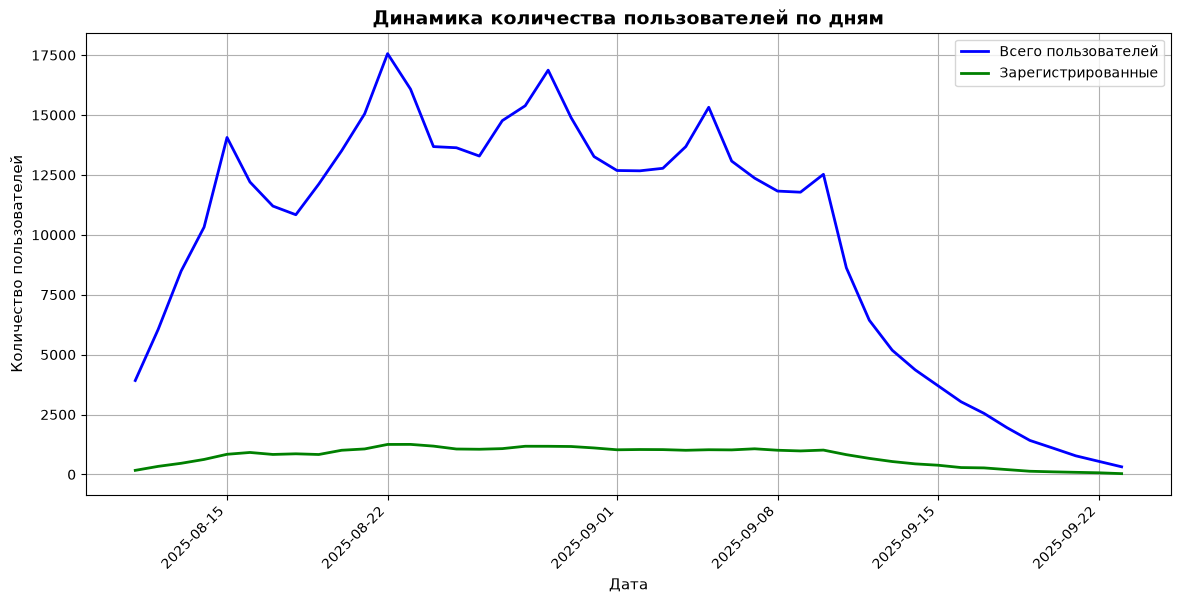

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(daily_stats['session_date'], daily_stats['total_users'], 
        label='Всего пользователей', color='blue', linewidth=2)
ax.plot(daily_stats['session_date'], daily_stats['registered_users'], 
        label='Зарегистрированные', color='green', linewidth=2)

ax.set_xlabel('Дата', fontsize=11)
ax.set_ylabel('Количество пользователей', fontsize=11)
ax.set_title('Динамика количества пользователей по дням', fontsize=14, fontweight='bold')
ax.grid(True, alpha=1)
plt.xticks(rotation=45, ha='right')
ax.legend(fontsize=10)
plt.show()

- <font color='#3127F5'> Общее количество пользователей колеблется до 17 500, но конверсия в зарегистрированных пользователей показывает стабильно низкие показатели, что критично для монетизации через подписку.
- <font color='#3127F5'> Пики общего трафика не конвертируются в рост зарегистрированной базы, это может говорить о том, что пользователи не видят ценности в регистрации.
- <font color='#3127F5'> Наблюдается спад активности ближе ко второй половине сентября, в причине которого нужно разбираться.

5. <font color='#3127F5'>Построим отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням:

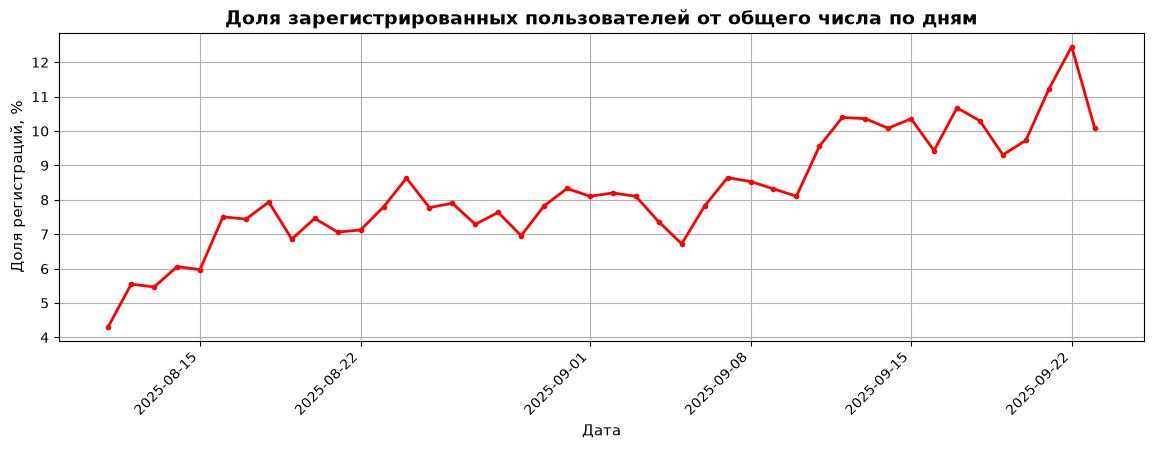

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_stats['session_date'], daily_stats['registration_rate'], 
        color='red', linewidth=2, marker='o', markersize=3)
ax.set_xlabel('Дата', fontsize=11)
ax.set_ylabel('Доля регистраций, %', fontsize=11)
ax.set_title('Доля зарегистрированных пользователей от общего числа по дням', fontsize=14, fontweight='bold')
ax.grid(True, alpha=1)
plt.xticks(rotation=45, ha='right')
plt.show()

<font color='#3127F5'> График показывает позитивную динамику конверсии. Доля регистраций выросла - с 4-5% в начале августа до пика 12.5% во второй половине сентября.
- <font color='#3127F5'> Если сопоставить это с предыдущим графиком (где общий трафик падал в конце периода, а число регистраций оставалось более стабильным), становится понятно, почему процент растет. Случайный трафик уходит, а остается более лояльная аудитория, которая готова регистрироваться.

#### <font color='#FF8585'>Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

Проанализируем число просмотренных страниц во время первых сессий пользователей. Найдём количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 8978 первых сессиях, две страницы — в 32 494 первых сессиях и так далее.

1. <font color='#3127F5'>Фильтруем только первые сессии пользователей:

In [13]:
first_sessions = sessions_history[sessions_history['session_number'] == 1].copy()
first_sessions.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


2. <font color='#3127F5'>Считаем количество сессий для каждого значения просмотренных страниц:

In [14]:
page_view_distribution = first_sessions['page_counter'].value_counts().sort_index()
page_view_distribution

page_counter
1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: count, dtype: int64

3. <font color='#3127F5'>Построим столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий:

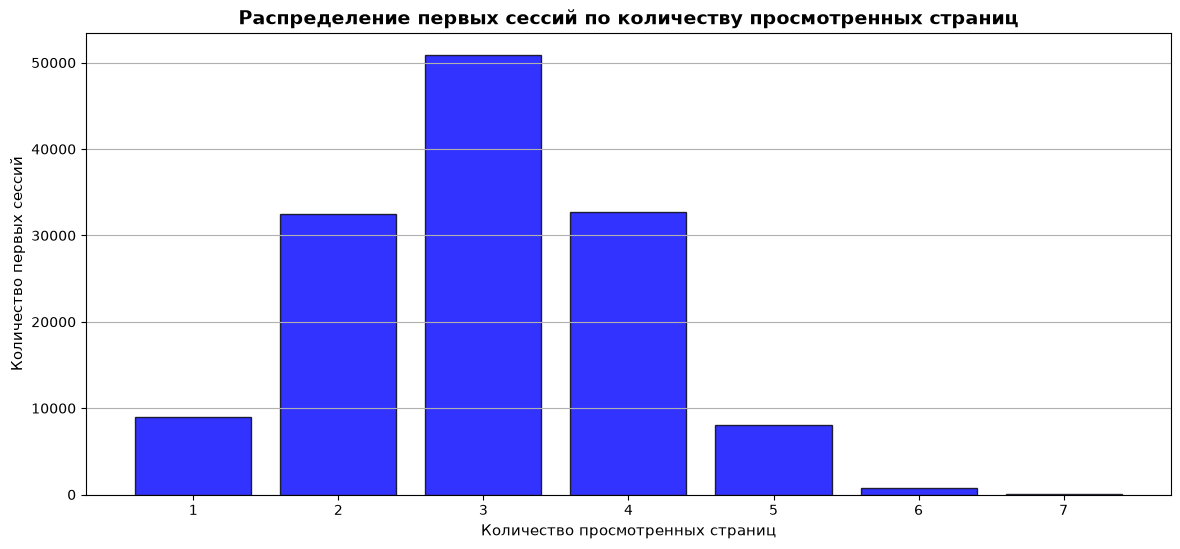

In [15]:
plt.figure(figsize=(14, 6))
plt.bar(
    page_view_distribution.index,
    page_view_distribution.values,
    color='blue',
    edgecolor='black',
    alpha=0.8)
plt.xlabel('Количество просмотренных страниц', fontsize=11)
plt.ylabel('Количество первых сессий', fontsize=11)
plt.title(
    'Распределение первых сессий по количеству просмотренных страниц',
    fontsize=14,
    fontweight='bold')
plt.grid(True, alpha=1, axis='y')
plt.show()

<font color='#3127F5'> Распределение количества просмотренных страниц в первых сессиях имеет форму, близкую к нормальному, с пиком на 3 страницах.
- <font color='#3127F5'> Большинство пользователей просматривают от двух до четырех страниц. Это показывает, как в среднем пользователи взаимодействуют с приложением.
- <font color='#3127F5'> Пользователи, просмотревшие 1 страницу, скорее всего, сразу закрыли приложение.
Пользователи, просмотревшие 3 и более страниц, демонстрируют интерес к контенту.

#### <font color='#FF8585'>Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

1. <font color='#3127F5'>В датафрейме `sessions_history` с фильтром по первым сессиям создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше:

In [16]:
first_sessions['good_session'] = (first_sessions['page_counter'] >= 4).astype(int)
first_sessions['good_session'].head()

0    0
1    1
2    1
3    1
4    0
Name: good_session, dtype: int64

2. <font color='#3127F5'>Группируем по дате и считаем долю `good_session`:


In [17]:
daily_good_session = first_sessions.groupby('session_date').agg(
    total_first_sessions=('session_id', 'count'),
    good_first_sessions=('good_session', 'sum')).reset_index()
daily_good_session['good_session_rate'] = (
    daily_good_session['good_first_sessions'] / daily_good_session['total_first_sessions'] * 100)
daily_good_session.head()

,session_date,total_first_sessions,good_first_sessions,good_session_rate
0,2025-08-11,3919,1226,31.283491
1,2025-08-12,4106,1225,29.834389
2,2025-08-13,5087,1561,30.686063
3,2025-08-14,5456,1741,31.909824
4,2025-08-15,7801,2427,31.111396


3. <font color='#3127F5'>Построим график со средним значением доли успешных первых сессий от всех первых сессий пользователей. Данные визуализируем по дням за весь период наблюдения:

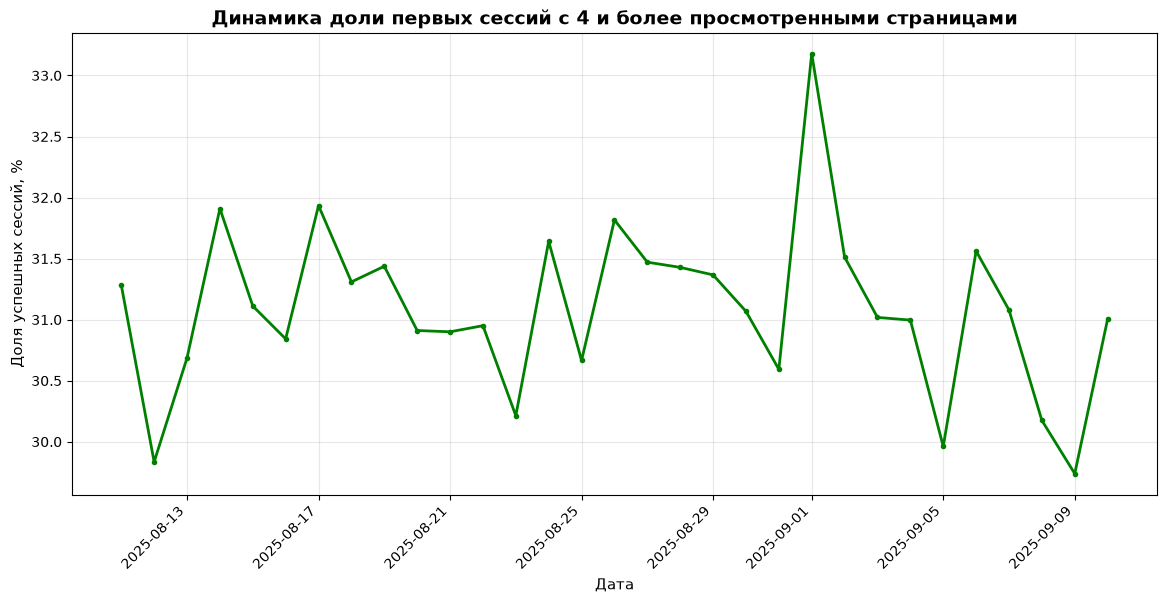

In [18]:
plt.figure(figsize=(14, 6))
plt.plot(daily_good_session['session_date'], daily_good_session['good_session_rate'], 
         color='green', linewidth=2, marker='o', markersize=3)
plt.xlabel('Дата', fontsize=11)
plt.ylabel('Доля успешных сессий, %', fontsize=11)
plt.title('Динамика доли первых сессий с 4 и более просмотренными страницами', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.show()

<font color='#3127F5'> График демонстрирует, что доля успешных сессий остается достаточно стабильной на протяжении всего периода наблюдения. Метрика колеблется в пределах около 30% - 33%.
- <font color='#3127F5'> На графике нет выраженного долгосрочного тренда на рост или падение. Всплески и падения носят краткосрочный характер.
- <font color='#3127F5'> В среднем около 31% первых сессий можно считать успешными.
    
<font color='#3127F5'> Из графика можно сделать вывод, что текущий алгоритм рекомендаций обеспечивает стабильный уровень вовлеченности пользователей.

### <font color='#FF8585'>Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### <font color='#FF8585'>Расчёт размера выборки
При расчёте размера выборки используем метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

In [43]:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода
power = 1 - beta  # Мощность теста
p = 0.30 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p*(1 + mde))

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### <font color='#FF8585'>Расчёт длительности A/B-теста

Используем данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитаем длительность теста, разделив одно на другое.

1. <font color='#3127F5'> Рассчитаем среднее количество уникальных пользователей приложения в день.

In [20]:
daily_unique_users = sessions_history.groupby('session_date')['user_id'].nunique()
avg_daily_users = daily_unique_users.mean()
avg_daily_users

np.float64(9907.363636363636)

2. <font color='#3127F5'> Определим длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлим в большую сторону.

In [21]:
users_per_group = int(np.ceil(sample_size))
test_duration = ceil(users_per_group / (avg_daily_users / 2))

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users:.0f} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907 пользователей в день составит 9 дней


<font color='#3127F5'>На основе исторических данных мы оценили среднее количество уникальных пользователей в день - 9 907 человек. При таком уровне трафика и рассчитанном размере выборки на одну группу 41 040 человек, минимально необходимое число пользователей набирается примерно за 9 дней.

Однако это оценка минимальной длительности с точки зрения статистики. В ходе эксперимента потребуется больше времени, чтобы сгладить случайные суточные колебания трафика, учесть недельную сезонность, дать пользователям адаптироваться к изменениям и повысить надёжность результатов.

### <font color='#FF8585'>Мониторинг А/В-теста

#### <font color='#FF8585'>Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие нас метрики корректно считаются.

1. <font color='#3127F5'> Считаем и сохраним в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

2. <font color='#3127F5'> Рассчитаем количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения:

In [23]:
users_by_group = (
    sessions_test_part
    .groupby('test_group')['user_id']
    .nunique()
    .reset_index(name='users_count'))
users_by_group

,test_group,users_count
0,A,1477
1,B,1466


3. <font color='#3127F5'> Рассчитаем и выведем на экран процентную разницу в количестве пользователей в группах A и B:

In [24]:
users_A = users_by_group.loc[users_by_group['test_group'] == 'A', 'users_count'].iloc[0]
users_B = users_by_group.loc[users_by_group['test_group'] == 'B', 'users_count'].iloc[0]
P = 100 * abs(users_A - users_B) / users_A
print(f'Процентная разница в количестве пользователей между группами A и B: {P:.2f}%')

Процентная разница в количестве пользователей между группами A и B: 0.74%


4. <font color='#3127F5'> Построим визуализацию для наглядности:

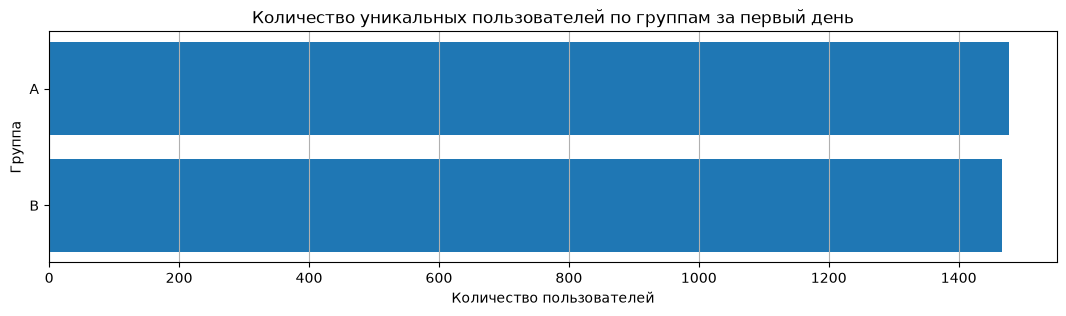

In [25]:
plt.figure(figsize=(13, 3))
plt.barh(['B', 'A'], [users_B, users_A])
plt.title('Количество уникальных пользователей по группам за первый день')
plt.ylabel('Группа')
plt.xlabel('Количество пользователей')
plt.grid(axis='x')
plt.show()

<font color='#3127F5'> Мы посчитали число уникальных пользователей в группах A и B за первый день теста и оценили процентную разницу между ними. Различия в объёмах трафика между группами 0.74% и соответствуют ожидаемому уровню случайного разброса при равномерном распределении. На визуализации видно, что группы по размеру примерно одинаковы, что является важным условием.

#### <font color='#FF8585'>Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

1. <font color='#3127F5'> Рассчитаем количество пользователей, которые встречаются одновременно в группах A и B, или убедимся, что таких нет.

In [26]:
users_in_A = set(sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'].unique())
users_in_B = set(sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'].unique())
intersection_users = users_in_A & users_in_B
print('Количество пользователей, попавших одновременно в обе группы:', len(intersection_users))

Количество пользователей, попавших одновременно в обе группы: 0


<font color='#3127F5'> Мы проверили, есть ли пользователи, которые одновременно попали в группы A и B. Пересечений мы не нашли, что говорит о независимости выборок.

#### <font color='#FF8585'>Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

1. <font color='#3127F5'> Вычислим долю каждого типа устройства для пользователей из группы A:

In [27]:
devices_A = (
    sessions_test_part[sessions_test_part['test_group'] == 'A']
    .groupby('device')['user_id']
    .nunique()
    .reset_index(name='users_count'))
devices_A['share'] = devices_A['users_count'] / devices_A['users_count'].sum()

2. <font color='#3127F5'> Вычислим долю каждого типа устройства для пользователей из группы B:

In [28]:
devices_B = (
    sessions_test_part[sessions_test_part['test_group'] == 'B']
    .groupby('device')['user_id']
    .nunique()
    .reset_index(name='users_count')
)
devices_B['share'] = devices_B['users_count'] / devices_B['users_count'].sum()

3. <font color='#3127F5'> Построим две диаграммы  с долями каждого типа устройства для пользователей из групп A и B и сравним их:

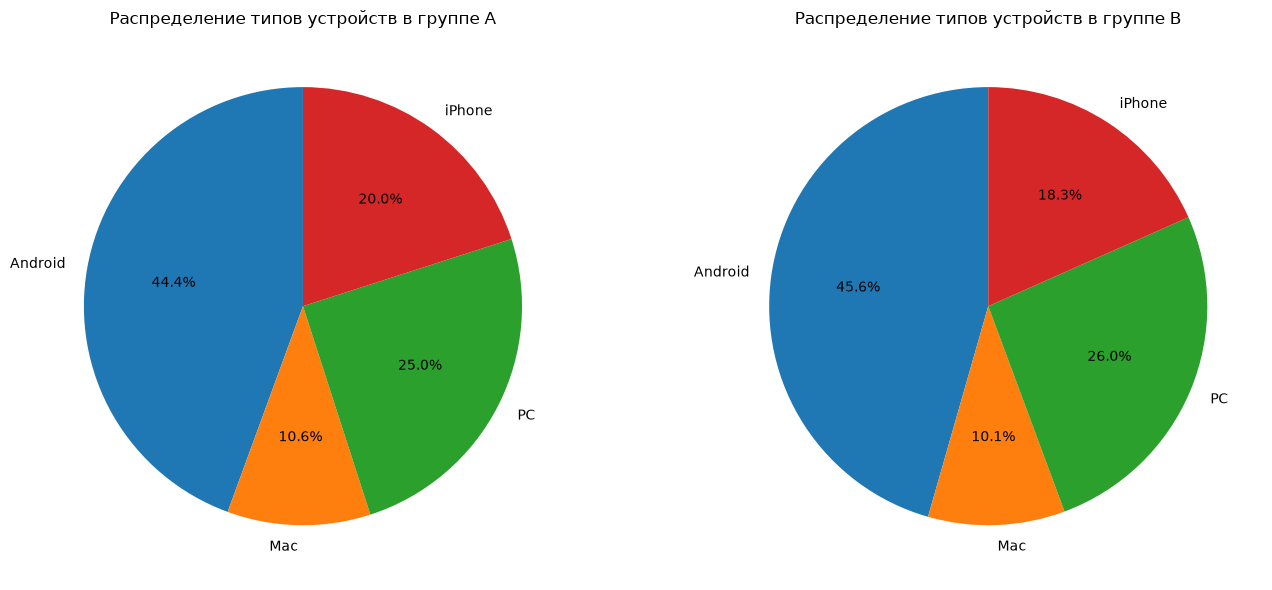

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(
    devices_A['share'],
    labels=devices_A['device'],
    autopct='%1.1f%%',
    startangle=90)
axes[0].set_title('Распределение типов устройств в группе A')

axes[1].pie(
    devices_B['share'],
    labels=devices_B['device'],
    autopct='%1.1f%%',
    startangle=90)
axes[1].set_title('Распределение типов устройств в группе B')
plt.tight_layout()
plt.show()

<font color='#3127F5'>Распределение устройств в группах A и B очень похоже:
- Android - разница 1.2%
- iPhone - разница 1.7%
- PC - разница 1%
- Mac - разница 0.5%

Это означает, что пользователи равномерно распределены по типам устройств между контрольной и тестовой группами.

#### <font color='#FF8585'>Равномерность распределения пользователей по регионам
Теперь убедимся, что пользователи равномерно распределены по регионам.

1. <font color='#3127F5'> Вычислим долю каждого региона для пользователей из группы A:

In [30]:
regions_A = (
    sessions_test_part[sessions_test_part['test_group'] == 'A']
    .groupby('region')['user_id']
    .nunique()
    .reset_index(name='users_count'))
regions_A['share'] = regions_A['users_count'] / regions_A['users_count'].sum()

2.  <font color='#3127F5'> Вычислим долю каждого региона для пользователей из группы B:

In [31]:
regions_B = (
    sessions_test_part[sessions_test_part['test_group'] == 'B']
    .groupby('region')['user_id']
    .nunique()
    .reset_index(name='users_count'))
regions_B['share'] = regions_B['users_count'] / regions_B['users_count'].sum()

3. <font color='#3127F5'> Построим две диаграммы с долей каждого региона для пользователей из групп A и B:

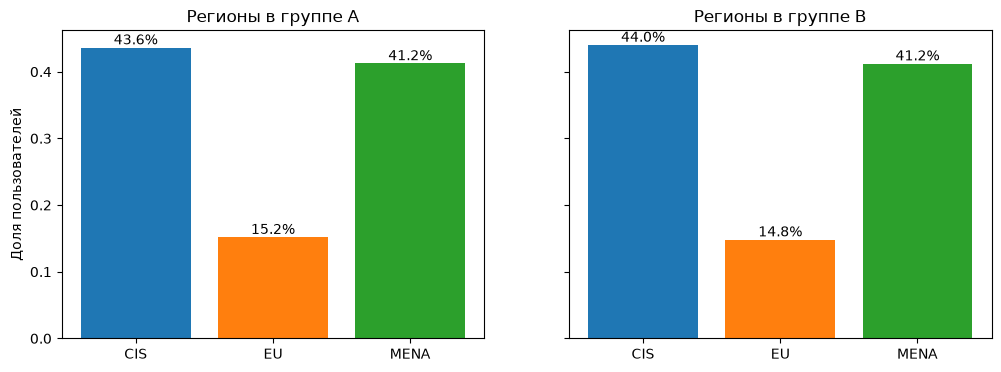

In [32]:
region_colors = {
    'CIS': '#1f77b4',
    'EU': '#ff7f0e',
    'MENA': '#2ca02c'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
#A
colors_A = [region_colors[r] for r in regions_A['region']]
axes[0].bar(regions_A['region'], regions_A['share'], color=colors_A)
axes[0].set_title('Регионы в группе A')
axes[0].set_ylabel('Доля пользователей')
for x, v in zip(regions_A['region'], regions_A['share']):
    axes[0].text(x, v, f'{v*100:.1f}%', ha='center', va='bottom')
#B
colors_B = [region_colors[r] for r in regions_B['region']]
axes[1].bar(regions_B['region'], regions_B['share'], color=colors_B)
axes[1].set_title('Регионы в группе B')
for x, v in zip(regions_B['region'], regions_B['share']):
    axes[1].text(x, v, f'{v*100:.1f}%', ha='center', va='bottom')
plt.show()

<font color='#3127F5'> Доли пользователей из разных регионов в группах A и B практически идентичны:
- CIS - разница 0.4%
- EU - разница 0.4%
- MENA - доля совпадает.

Это означает, что распределение пользователей по регионам в группах A и B статистически одинаковое. Можно переходить к анализу результатов A/B-теста.

---
#### <font color='#FF8585'>Вывод после проверки A/B-теста
---

<font color='#3127F5'> По результатам анализа данных первого дня A/B‑теста можно сделать следующие выводы:

- Количество пользователей в группах A и B примерно одинаково, а процентная разница в 0.74% находится в допустимых пределах для случайного распределения.
- Пересечений пользователей между группами A и B не обнаружено, выборки независимы.
- Распределение пользователей по типам устройств в группах A и B выглядит сопоставимо, явных перекосов нет:
    - Android - разница 1.2%.
    - iPhone - разница 1.7%.
    - PC - разница 1.0%.
    - Mac - разница 0.5%.
- Аналогично распределение пользователей по регионам в обеих группах выглядит близким по структуре:
    - CIS - разница 0.4%.
    - EU - разница 0.4%.
    - MENA - доли совпадают полностью.

Это означает, что эксперимент запущен корректно, распределение по группам равномерно и независимо, а категориальные признаки не нарушают рандомизацию. Можно переходить к анализу итогов теста.

### <font color='#FF8585'>Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### <font color='#FF8585'>Получение результатов теста и подсчёт основной метрики

1. <font color='#3127F5'> Считаем и сохраним в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

In [33]:
sessions_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 100005 entries, 0 to 100004
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   user_id            100005 non-null  str  
 1   session_id         100005 non-null  str  
 2   session_date       100005 non-null  str  
 3   session_start_ts   100005 non-null  str  
 4   install_date       100005 non-null  str  
 5   session_number     100005 non-null  int64
 6   registration_flag  100005 non-null  int64
 7   page_counter       100005 non-null  int64
 8   region             100005 non-null  str  
 9   device             100005 non-null  str  
 10  test_group         100005 non-null  str  
dtypes: int64(3), str(8)
memory usage: 16.1 MB


2. <font color='#3127F5'>Преобразуем столбец `session_date` в формат `datetime`:

In [34]:
sessions_test['session_date'] = pd.to_datetime(sessions_test['session_date'])
sessions_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 100005 entries, 0 to 100004
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            100005 non-null  str           
 1   session_id         100005 non-null  str           
 2   session_date       100005 non-null  datetime64[us]
 3   session_start_ts   100005 non-null  str           
 4   install_date       100005 non-null  str           
 5   session_number     100005 non-null  int64         
 6   registration_flag  100005 non-null  int64         
 7   page_counter       100005 non-null  int64         
 8   region             100005 non-null  str           
 9   device             100005 non-null  str           
 10  test_group         100005 non-null  str           
dtypes: datetime64[us](1), int64(3), str(7)
memory usage: 15.1 MB


3. <font color='#3127F5'>Найдем период проведения A/B теста:

In [35]:
start_date = sessions_test['session_date'].min()
end_date = sessions_test['session_date'].max()
print(f"Период проведения A/B-теста: с {start_date.date()} по {end_date.date()}")

Период проведения A/B-теста: с 2025-10-14 по 2025-11-02


4. <font color='#3127F5'>Найдём общее количество уникальных пользователей за весь период теста и посмотрим, как произошло разделение пользователей по группам:

In [36]:
total_unique_users = sessions_test['user_id'].nunique()
print(f"\nОбщее количество уникальных пользователей за период теста: {total_unique_users}")
users_by_group = (
    sessions_test
    .groupby('test_group')['user_id']
    .nunique()
    .reset_index(name='Количество пользователей'))
total_users = users_by_group['Количество пользователей'].sum()
users_by_group['Доля от общего кол-ва'] = users_by_group['Количество пользователей'] / total_users
users_by_group


Общее количество уникальных пользователей за период теста: 30579


,test_group,Количество пользователей,Доля от общего кол-ва
0,A,15163,0.495863
1,B,15416,0.504137


- <font color='#3127F5'>Исходя из полученных сведений, можно сказать, что мы не достигли ранее расчитанного показателя в 41 040 пользователей на группу за 9 дней, фактически набрав по 15тыс. пользователей на группы за 20 дней. Это может означать, что при анализе мы заметим только более крупные эффекты, чем могли бы.
- Распределение пользователей между группами сбалансированно, без сильных перекосов.
- Данные захватывают и будни, и выходные, позволяя учесть недельную сезонность.

5. <font color='#3127F5'>В датафрейме `sessions_test` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено *4 и более страниц*, и значение `0`, если просмотрено *меньше*.

In [37]:
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


- <font color='#3127F5'>Мы загрузили полный датасет A/B‑теста и добавили в него признак `good_session`, отражающий успешные сессии с четырьмя и более просмотренными страницами. Эта метрика будет использоваться далее как основа для сравнения вовлечённости между группами A и B.

#### <font color='#FF8585'>Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

- <font color='#3127F5'>Команда разработчиков тестирует новый алгоритм рекомендательных систем, который, по их мнению, будет показывать более интересный контент для каждого пользователя. У нас есть подходящая метрика вовлечённости - доля успешных первых сессий, в рамках которых пользователь просмотрел 4 и более страниц (`good_session = 1`). Она принимается как **целевая метрика**.
- **Нулевая гипотеза** - доля успешных первых сессий в группах A и B одинакова, внедрение нового алгоритма рекомендаций не влияет на вовлечённость пользователей.
- **Альтернативная гипотеза** - доля успешных первых сессий в группе B с новым алгоритмом выше, чем в группе A, то есть новый алгоритм увеличивает вовлечённость.
- Возможные **прокси-метрики**, которые можно было бы дополнительно отслеживать:
    - В имеющихся данных нет столбца с временем окончания сессии или с длительностью, полезно было бы длительность сессии тоже отслеживать, если пользователь долго сидит в приложении, возможно, оно ему интересно.
    - Вернувшиеся пользователи на следующий день (в %). Это напрямую показывает вовлеченность.
    - Сколько в среднем пользователи смотрят страниц за сессию помогло бы оценить эффект от нововведений еще более детально.
- Возможные **барьерные метрики**:
    - В имеющихся данных таких нет, но полезно было бы знать долю технических ошибок, долю сессий с очень долгой загрузкой контента.
    - Процент оформления платной подписки, если пользователям что-то не нравится, вряд ли они будут покупать подписку.

<font color='#3127F5'> ***Мы определили, что в предоставленных данных разумно использовать долю успешных первых сессий как ключевую метрику нового алгоритма. Сформулировали нулевую и альтернативную гипотезы, а также обозначили дополнительные прокси и барьерные метрики, которые можно было бы отслеживать при проведении подобного эксперимента в реальном продукте.***


#### <font color='#FF8585'>Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используем созданный на первом шаге задания столбец `good_session` и рассчитаем долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразим на экране.

1. <font color='#3127F5'> Возьмём только первые сессии пользователей в период теста:

In [38]:
first_sessions_test = sessions_test[sessions_test['session_number'] == 1]

2. <font color='#3127F5'> Найдём долю успешных первых сессий по группам:

In [39]:
good_share_by_group = (
    first_sessions_test
    .groupby('test_group')['good_session']
    .mean()
    .reset_index(name='good_share'))
good_share_by_group

,test_group,good_share
0,A,0.315724
1,B,0.314673


In [40]:
good_A = good_share_by_group.loc[good_share_by_group['test_group'] == 'A', 'good_share'].iloc[0]
good_B = good_share_by_group.loc[good_share_by_group['test_group'] == 'B', 'good_share'].iloc[0]
diff = good_B - good_A
print(f"Разница B-A: {diff}")

Разница B-A: -0.0010504523811919464


<font color='#3127F5'> - Мы сравнили долю успешных первых сессий между группами A и B. Доли в обеих группах близки, а разница невелика - всего 0.001%. Можно предположить, что новый алгоритм рекомендаций **не привёл к заметному росту или падению вовлечённости**, но для окончательного вывода **требуется статистический тест**.

#### <font color='#FF8585'>Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге мы убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

1. <font color='#3127F5'> Рассчитаем количество успешных сессий и количество всех сессий по группам:

In [41]:
good_sessions_by_group = first_sessions_test.groupby('test_group')['good_session'].sum()
total_sessions_by_group = first_sessions_test.groupby('test_group')['good_session'].count()

2. <font color='#3127F5'> Теперь нам нужно понять, наблюдаемая разница долей могла возникнуть случайно или она статистически значима? Для этого здесь подошел бы z-test. Применим его:

In [42]:
good_sessions_A = good_sessions_by_group['A']
good_sessions_B = good_sessions_by_group['B']
total_sessions_A = total_sessions_by_group['A']
total_sessions_B = total_sessions_by_group['B']

stat, pvalue = proportions_ztest(count=[good_sessions_A, good_sessions_B],
                                 nobs=[total_sessions_A, total_sessions_B],
                                 alternative='two-sided')
print(f"pvalue={pvalue}")
alpha = 0.05
if pvalue > alpha:
    print('Нулевая гипотеза подтверждается')
    print('Статистически значимых различий в доле успешных первых сессий между группами A и B не обнаружено')
else:
    print('Нулевая гипотеза не подтверждается')
    print('Различия в доле успешных первых сессий между группами A и B статистически значимы')

pvalue=0.8432952701624264
Нулевая гипотеза подтверждается
Статистически значимых различий в доле успешных первых сессий между группами A и B не обнаружено


<font color='#3127F5'> Мы применили `z‑test` для сравнения долей успешных первых сессий в группах A и B и получили значение **p-value = 0.8433**. При **уровне значимости 0.05** у нас **нет оснований отвергать нулевую гипотезу**. Получается, что различия в долях успешных сессий между группами статистически незначимы и разница может быть объяснена случайными колебаниями, а не влиянием нового алгоритма.

#### <font color='#FF8585'>Вывод по результатам A/B-эксперимента

<font color='#3127F5'>

**Вывод**
- A/B‑тест проводился в период с `2025‑10‑14` по `2025‑11‑02` включительно. За это время в эксперименте участвовало `30 579` уникальных пользователей. Из них `15 163` пользователя попали в контрольную группу A, а `15 416` — в тестовую группу B, то есть трафик разделился между вариантами практически поровну (около `49.6%` и `50.4%` от общего числа участников). При планировании теста рассчитывался больший необходимый объём выборки (`41 040` пользователей на группу за `9` дней), однако в реальности за `20` дней набрали около `15` тысяч пользователей в каждую группу. Это означает, что мощность теста ниже плановой и мы уверенно можем увидеть только эффекты заметной величины, тогда как слабые эффекты могли остаться неотличимыми от шума.
    
1. **Ключевая метрика**
    - Ключевой метрикой была доля успешных первых сессий, в рамках которых пользователь просмотрел 4 и более страниц. Для анализа мы рассмотрели только первые сессии пользователей в период теста. Доля успешных первых сессий в группе A составила примерно 31.57%, а в группе B — около 31.47%. Разница (B − A) оказалась отрицательной и очень небольшой - примерно -0.0011. Это означает, что новый алгоритм рекомендаций не демонстрирует ни заметного улучшения, ни ухудшения вовлечённости.
    
2. **Статистическая значимость результатов**
    - Для проверки статистической значимости наблюдаемой разницы в долях успешных первых сессий мы применили z‑тест для двух пропорций. Тест учитывает количество успешных первых сессий и общее количество первых сессий в каждой группе и проверяет нулевую гипотезу о равенстве долей. Расчёты дали значение `p‑value ≈ 0.8433`. При уровне значимости `0.05`, `p‑value` значительно больше порогового значения, поэтому у нас нет оснований отвергать нулевую гипотезу. Различия в доле успешных первых сессий между группами A и B статистически незначимы и с высокой вероятностью могут быть объяснены случайным шумом, а не действием нового алгоритма.

**Рекомендации по внедрению**

С учётом того, что тест шёл почти три недели и охватывал более 30 тысяч уникальных пользователей, при этом:
- распределение пользователей по группам было сбалансированным
- значения целевой метрики в группах A и B практически совпали
- p‑value существенно превышает 0.05 и не даёт оснований говорить о статистически значимом эффекте

внедрять новый алгоритм рекомендаций как более эффективный вариант на основе этого эксперимента нецелесообразно. Текущий тест не показывает ни прироста ключевой метрики, ни её ухудшения. Если команда разработки считает, что алгоритм потенциально перспективен, имеет смысл либо доработать модель и перезапустить эксперимент с более сильной ожидаемой разницей, либо спроектировать дополнительный тест с другим набором метрик и более строгим контролем мощности.